# MEFISTO on the SEU-3D E8.0 embryos: where I am stuck

I fit MEFISTO and plain MOFA (mofapy2 0.7.5) to the two E8.0 mouse embryos of the SEU-3D digital embryo (Xie et al., Cell 2025). One matrix entry is the log-normalised SCT count of one gene in one Stereo-seq cell bin, and one row is one bin (median about 1,200 counts over 16,000 genes). 2,500 bins per embryo, 2,000 variable genes, 12 factors, with the embryos as groups and (x, y, z) as covariates. MEFISTO is MOFA with a different prior on each factor: a weighted average of MOFA's independent prior and a Gaussian process over the coordinates, with covariance kernels over both the groups (here groups = embryos) and space.

**Settled:** the low per-entry variance explained is a depth effect, not the factors (report in my last email; `variance_explained.ipynb` in this repo has the full argument).

**Stuck:** why MEFISTO does worse than plain MOFA on data this spatial. The tables below are the evidence- the fits themselves come from `fit.py` and are loaded here.


In [1]:
import numpy as np, pandas as pd
from IPython.display import Image, display
from analysis import load_model, active_factors, pseudobulk_r2
JOINT = 'data/e8_joint_2500per.h5ad'
M = {'MEFISTO': load_model('models/mefisto_e8_2500per_K12.hdf5'), 'MOFA': load_model('models/mofa_e8_2500per_K12.hdf5')}
clf = pd.read_csv('classifier_summary.csv', index_col=[0, 1])
pb = pd.concat({k: pseudobulk_r2(m, JOINT) for k, m in M.items()}, names=['model']).reset_index(level=1, drop=True)
H = pd.read_csv('heldout_summary.csv')

## The gap

The spatial model loses on every per-cell score. R2 is mofapy2's per-embryo variance explained. "cell-type means" scores the same reconstruction after averaging the bins of each published cell type (types with at least 25 bins). Germ-layer accuracy is a cross-validated logistic regression from the factor scores to the three germ layers (balanced accuracy, chance 0.33).


In [2]:
rows = {}
for k, m in M.items():
    p = pb.loc[k].set_index('embryo')
    rows[k] = {'R2 rep1 (%)': m['r2_total']['E8.0_rep1'], 'R2 rep2 (%)': m['r2_total']['E8.0_rep2'],
               'R2 on cell-type means rep1 (%)': p.loc['E8.0_rep1', 'r2_pseudobulk'], 'R2 on cell-type means rep2 (%)': p.loc['E8.0_rep2', 'r2_pseudobulk'],
               'germ-layer accuracy': clf.loc[(k, 'germ layer'), 'balanced accuracy'], 'active factors': len(active_factors(m))}
stuck = pd.DataFrame(rows).T.round(2)
stuck.loc['MEFISTO / MOFA'] = (stuck.loc['MEFISTO'] / stuck.loc['MOFA']).round(2)
stuck

,R2 rep1 (%),R2 rep2 (%),R2 on cell-type means rep1 (%),R2 on cell-type means rep2 (%),germ-layer accuracy,active factors
MEFISTO,2.73,4.01,54.83,50.85,0.71,7.00
MOFA,6.90,9.05,78.35,74.65,0.86,12.00
MEFISTO / MOFA,0.40,0.44,0.70,0.68,0.83,0.58


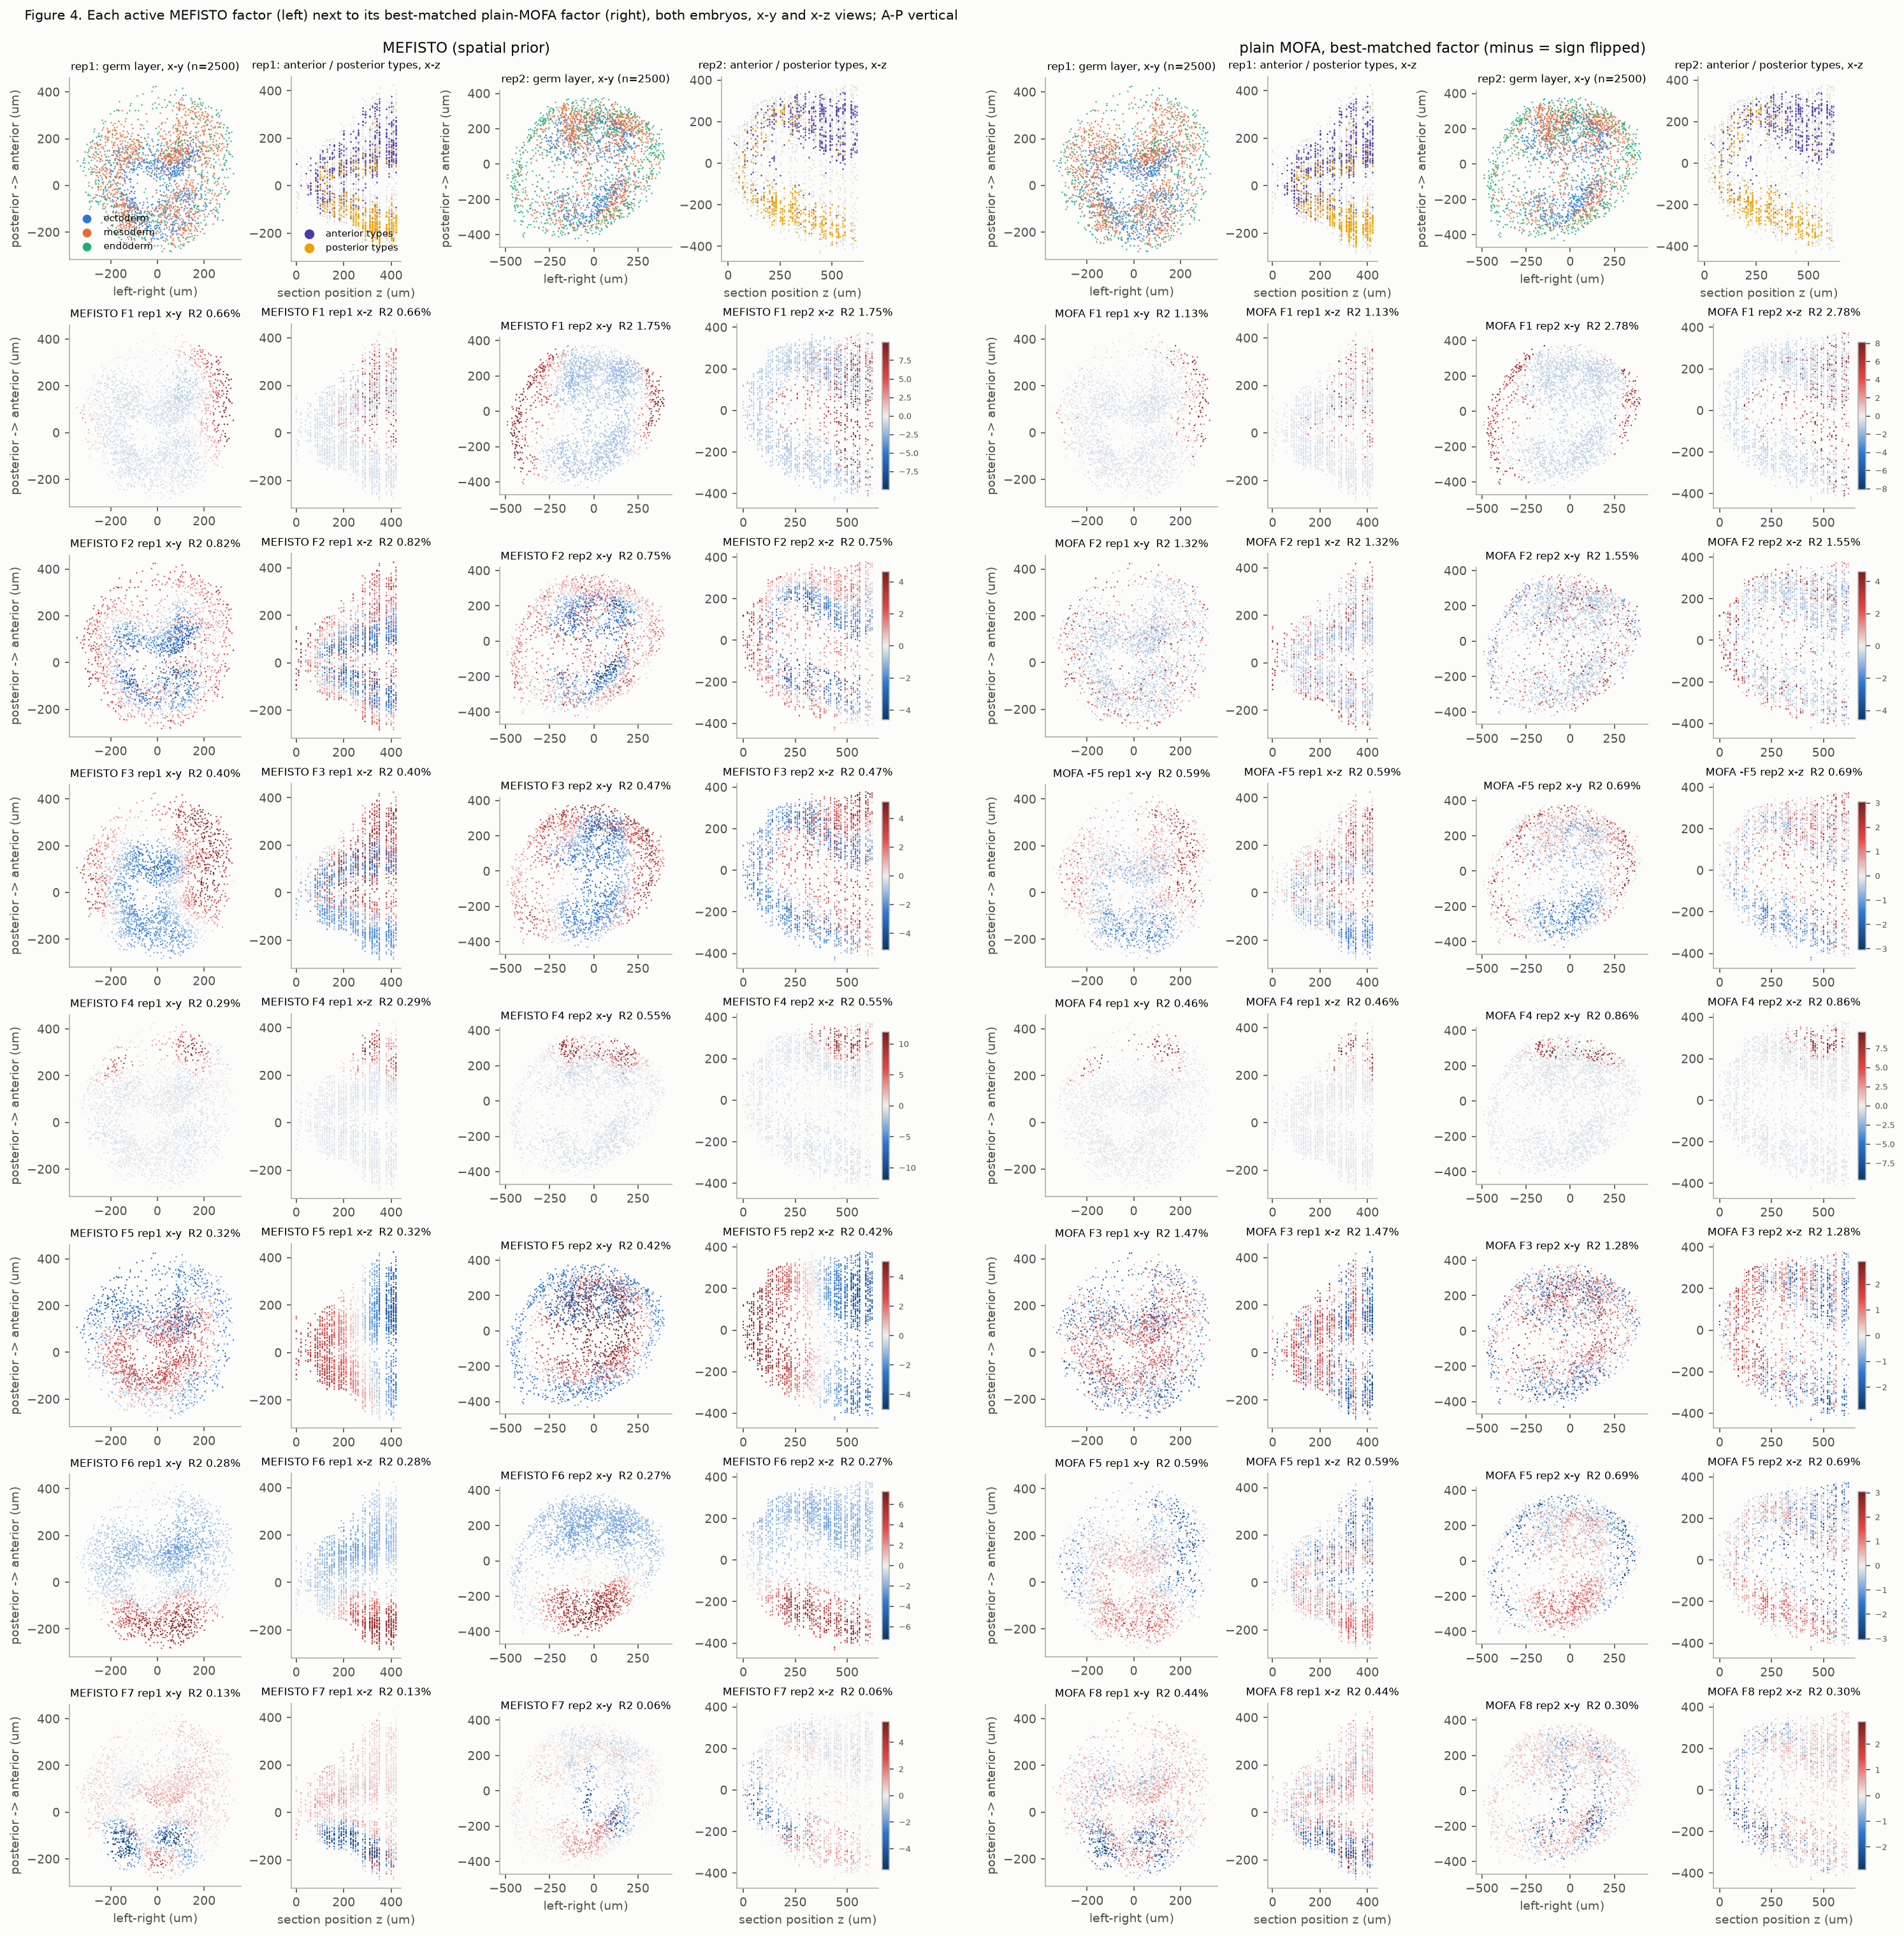

In [3]:
display(Image('figures/fig4_mefisto_vs_mofa_space.png'))

Figure 4 puts each active MEFISTO factor next to its best-matched MOFA factor, for both embryos. Here the MEFISTO-to-MOFA R2 ratio is 0.40, whereas on the MEFISTO paper's own Visium data it is 0.86 at full depth and 0.72 after thinning to 1,200 counts per spot, so depth explains part of the gap but not the rest. I do not have the mechanism.


## Why I am stuck

Potential hypotheses/reasoning as per why MOFA outperforms MEFISTO here. Some have issues, but noting my thinking here.


### A. Sampling noise

A MOFA factor has an independent standard-normal prior per cell, so it can absorb per-bin sampling noise, whereas a smooth factor cannot. If that were the whole gap, MOFA's lead would vanish on hidden entries and on cell-type means, since the per-bin noise is gone there.

Held-out test A (`heldout.py`, 1,000 bins per embryo, three seeds): 10% of the entries of every bin are hidden and the reconstruction is scored on just those.


In [4]:
H[H.test == 'A'].pivot_table(index='model', columns='embryo', values=['r', 'mse']).round(3)

mse                   r          
embryo    E8.0_rep1 E8.0_rep2 E8.0_rep1 E8.0_rep2
model                                            
MEFISTO       0.195     0.198     0.434     0.474
MOFA          0.191     0.192     0.454     0.497
gene mean     0.199     0.204     0.414     0.447

In [5]:
pb[['embryo', 'r2_cell', 'r2_pseudobulk', 'between_type_share']].round(2)

,embryo,r2_cell,r2_pseudobulk,between_type_share
model,,,,
MEFISTO,E8.0_rep1,2.73,54.83,3.46
MEFISTO,E8.0_rep2,4.01,50.85,5.15
MOFA,E8.0_rep1,6.90,78.35,3.46
MOFA,E8.0_rep2,9.05,74.65,5.15


**Partly true, not the whole story.** On hidden entries MOFA's 2.5x in-sample lead shrinks to 0.02 in correlation, so most of the per-entry gap is likely just noise-fitting. However, the gap survives averaging within cell type (78 vs 55%), where the per-bin noise is divided away- so what MEFISTO drops is structured.

**Remaining unexplained:** as above, the part of the gap that survives averaging within cell type (78 vs 55%)- that is structure, not noise.


### B. The smooth prior discards real, non-smooth biology

MEFISTO's factor prior is a Gaussian process with a stationary squared-exponential kernel and one lengthscale per factor, so variation that is not smooth at that lengthscale is left unexplained by construction. Cell identity at E8.0 is patchy: sheets a few cells thick, sharp boundaries between them, and scattered populations. If this is the mechanism, the labels that are sheets and boundaries should be the ones MEFISTO's factors lose.


In [6]:
clf.round(3)

factors  classes  balanced accuracy  macro F1  \
model   target                                                      
MEFISTO germ layer        7        3              0.709     0.715   
        cell type         7       17              0.374     0.365   
MOFA    germ layer       12        3              0.859     0.862   
        cell type        12       17              0.457     0.451   

                    baseline balanced accuracy  baseline macro F1  
model   target                                                     
MEFISTO germ layer                       0.333              0.206  
        cell type                        0.059              0.017  
MOFA    germ layer                       0.333              0.206  
        cell type                        0.059              0.017

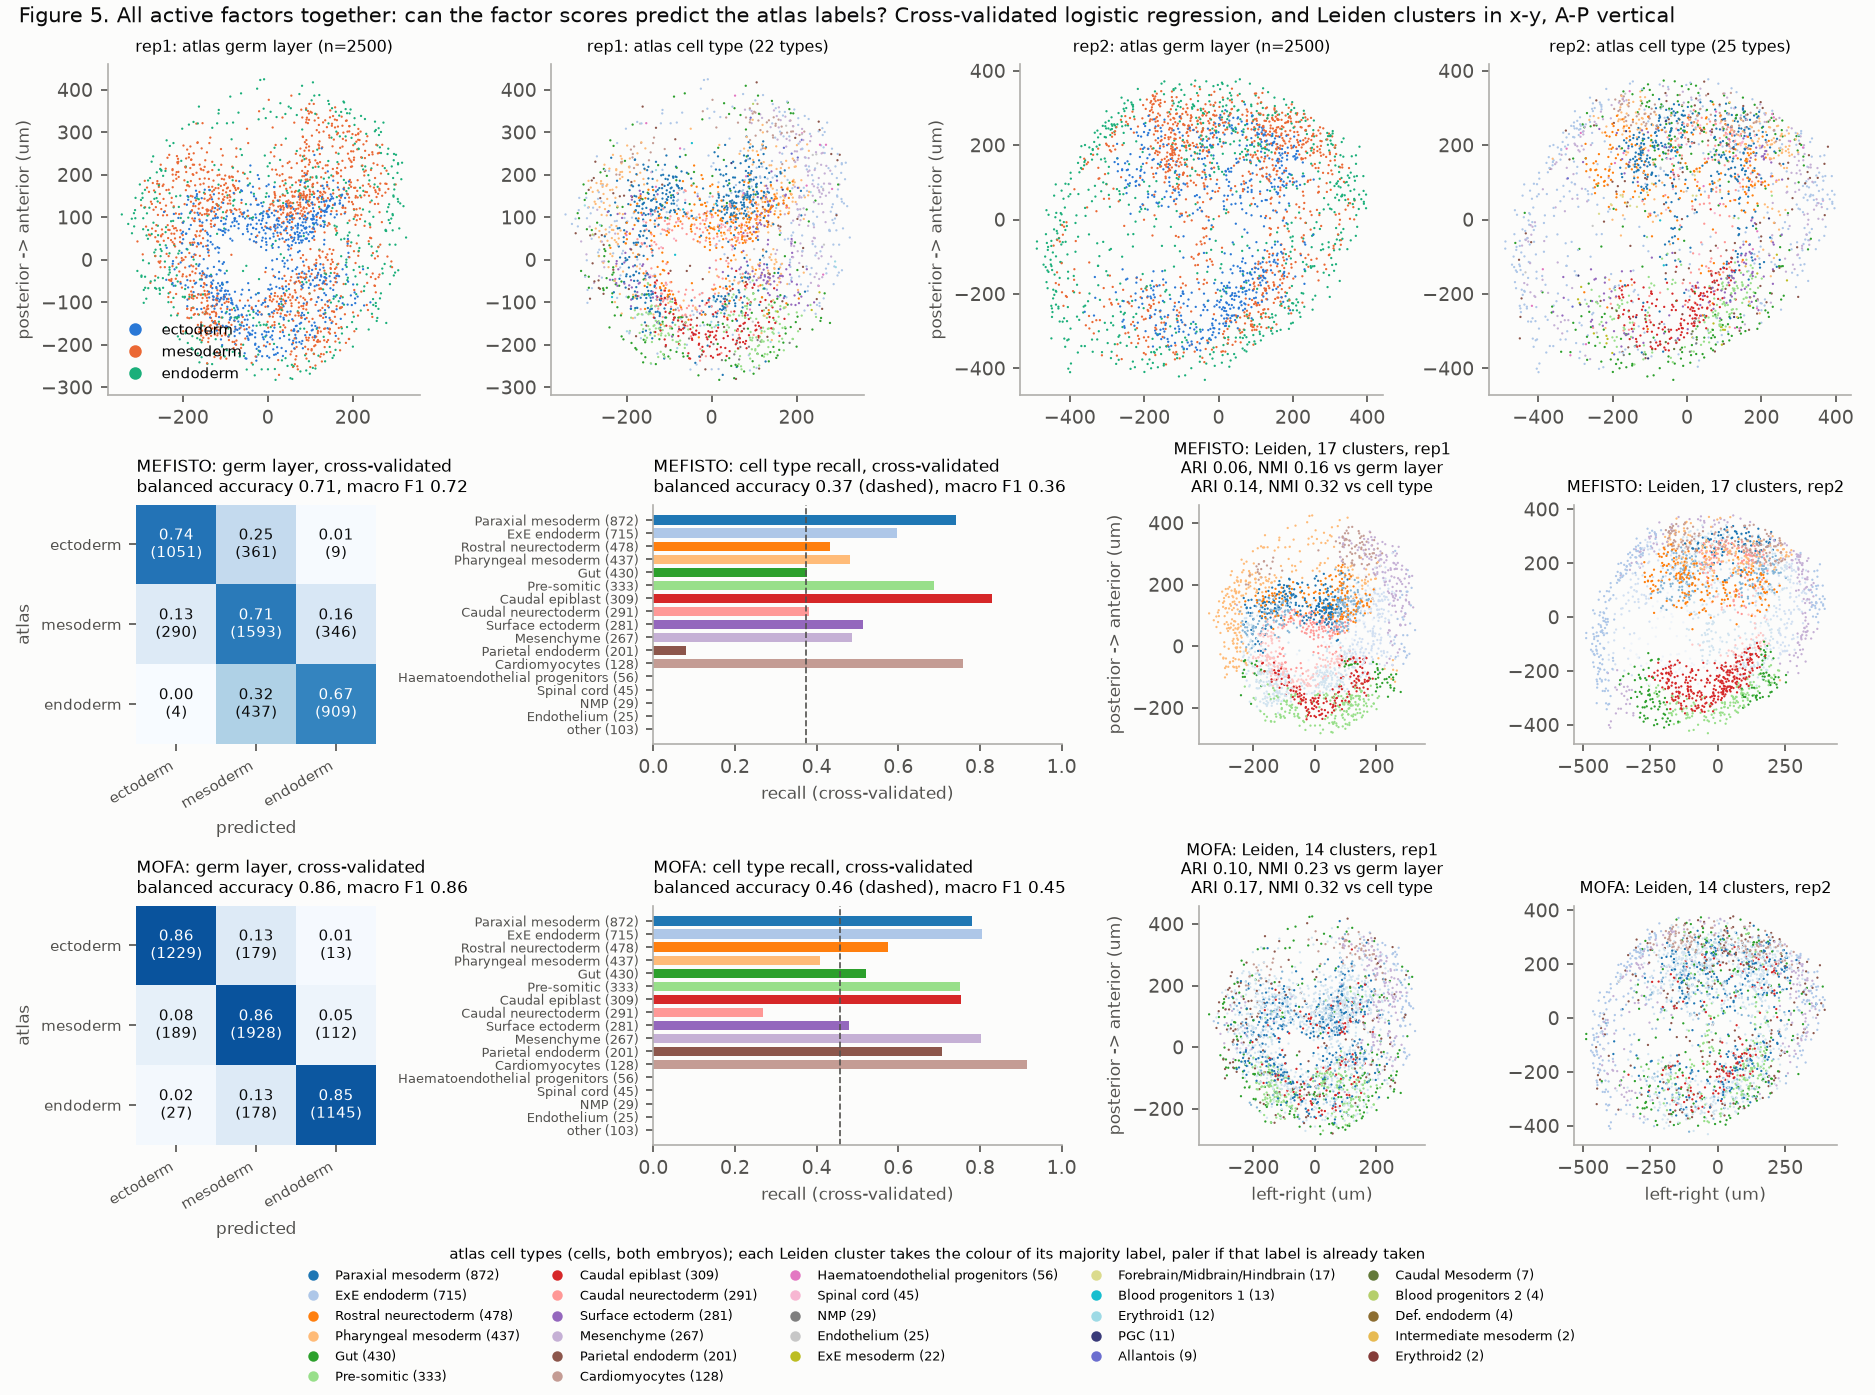

In [7]:
display(Image('figures/fig5_all_factors_vs_atlas.png'))

**Consistent with everything measured, not tested directly.** Germ layer is the most spatial label there is, and it still drops from 0.86 to 0.71 (cell type drops from 0.46 to 0.37).


One thing to rule out first: that the sparse GP's inducing grid is simply too coarse for the sheets. Measured from the atlas, it isn't.


In [10]:
import anndata as ad
from scipy.spatial import cKDTree
ATLAS = {'E8.0_rep1': 'data/GSM9046247_Embryo_E8.0_stereo_rep1.h5ad', 'E8.0_rep2': 'data/GSM9046248_Embryo_E8.0_stereo_rep2.h5ad'}
nn = lambda P: np.median(cKDTree(P).query(P, k=2)[0][:, 1])   # median nearest-neighbour distance, 3D
# mofapy2's inducing points: every (1/frac_inducing)-th sample along x+y+z over the pooled bins (gp_utils.set_inducing_points, random=False)
kept = pd.concat(m['obs'], names=['group']).reset_index(level=0)
loc = kept[['x', 'y', 'z']].sum(axis=1).to_numpy(); order = np.lexsort((np.random.default_rng(0).random(len(kept)), loc))
n_ind = int(max(0.1 * len(kept), 100)); ind = kept.iloc[order[np.floor(np.arange(0, len(kept), len(kept) / n_ind)).astype(int)]]
geo = {}
for g, o in m['obs'].items():
    a = ad.read_h5ad(ATLAS[g], backed='r').obs
    P = a[['x', 'y', 'z']].to_numpy(float); gl = a.germ_layer.astype(str).to_numpy(); d = []
    for z in np.unique(P[:, 2]):   # per section: distance from each cell to the nearest cell of a different germ layer
        s = P[:, 2] == z; Q = P[s][:, :2]; G = gl[s]
        for L in np.unique(G):
            k = G == L
            if k.sum() >= 3 and (~k).sum() >= 3: d.append(cKDTree(Q[~k]).query(Q[k])[0])
    d = np.concatenate(d); I = ind[ind.group == g]
    geo[g] = {'cells in atlas': len(a), 'sections': a.z.nunique(), 'cell spacing (um)': round(nn(P), 1),
              'distance to another germ layer, median (um)': round(np.median(d)), 'same, 90th pct (um)': round(np.percentile(d, 90)),
              'kept bins': len(o), 'kept-bin spacing (um)': round(nn(o[['x', 'y', 'z']].to_numpy(float))),
              'inducing points': len(I), 'inducing spacing (um)': round(nn(I[['x', 'y', 'z']].to_numpy(float)))}
ls = m['lengthscale'][active_factors(m)]
print(f'learned lengthscales of the active factors: {ls.min():.0f} to {ls.max():.0f} um')
pd.DataFrame(geo)


learned lengthscales of the active factors: 42 to 288 um


,E8.0_rep1,E8.0_rep2
cells in atlas,11048.0,27266.0
sections,35.0,52.0
cell spacing (um),10.9,10.9
"distance to another germ layer, median (um)",26.0,27.0
"same, 90th pct (um)",48.0,51.0
kept bins,2500.0,2500.0
kept-bin spacing (um),15.0,21.0
inducing points,237.0,263.0
inducing spacing (um),37.0,44.0


Cells are 11 um apart, and a typical cell sits 26 um from the nearest cell of another germ layer (90% within 50 um), so a sheet is about 50 um thick- 4 to 5 cells. The 2,500 bins I kept are 15 to 21 um apart, and mofapy2's inducing points (a subset of those bins, about 250 per embryo) are 37 to 44 um apart, under one sheet thickness. So the grid can resolve the sheets; what can't follow a sheet is the smooth part itself, since the learned lengthscales are 42 to 288 um, all at or above the sheet thickness. (The two embryos are also not in a common coordinate frame; an anterior-posterior aligned refit is in `extra/`.)

**Remaining unexplained:** as above, whether the loss really is the boundaries- nothing here tests it directly.


### C. Fitting path: five factors died

MEFISTO's prior on each factor is a mix: scale x spatial kernel + (1 - scale) x identity, with the scale and lengthscale learned. At scale 0 the factor has MOFA's prior, so a non-smooth factor could in principle survive as a plain MOFA factor. The claim: MEFISTO loses partly because it ends with 7 factors instead of 12, and the pruning is a side effect of the GP fit, not of the data.


In [8]:
m = M['MEFISTO']
fac = pd.DataFrame({'R2 rep1 (%)': m['r2'].iloc[:, 0], 'R2 rep2 (%)': m['r2'].iloc[:, 1], 'GP scale': m['smoothness'],
                    'lengthscale (um)': m['lengthscale'], 'sharedness': m['sharedness']}).round(2)
fac['active'] = fac.index.isin(active_factors(m))
fac

,R2 rep1 (%),R2 rep2 (%),GP scale,lengthscale (um),sharedness,active
F1,0.66,1.75,0.59,109.48,0.00,True
F2,0.82,0.75,0.49,109.48,0.58,True
F3,0.40,0.47,0.68,109.48,0.00,True
F4,0.29,0.55,0.66,41.66,0.05,True
F5,0.32,0.42,0.56,287.69,0.75,True
F6,0.28,0.27,0.72,109.48,0.00,True
F7,0.13,0.06,0.80,41.66,0.27,True
F8,0.00,0.00,0.05,15.85,0.00,False
F9,0.00,0.00,0.10,41.66,0.00,False
F10,0.00,0.00,0.01,287.69,1.00,False


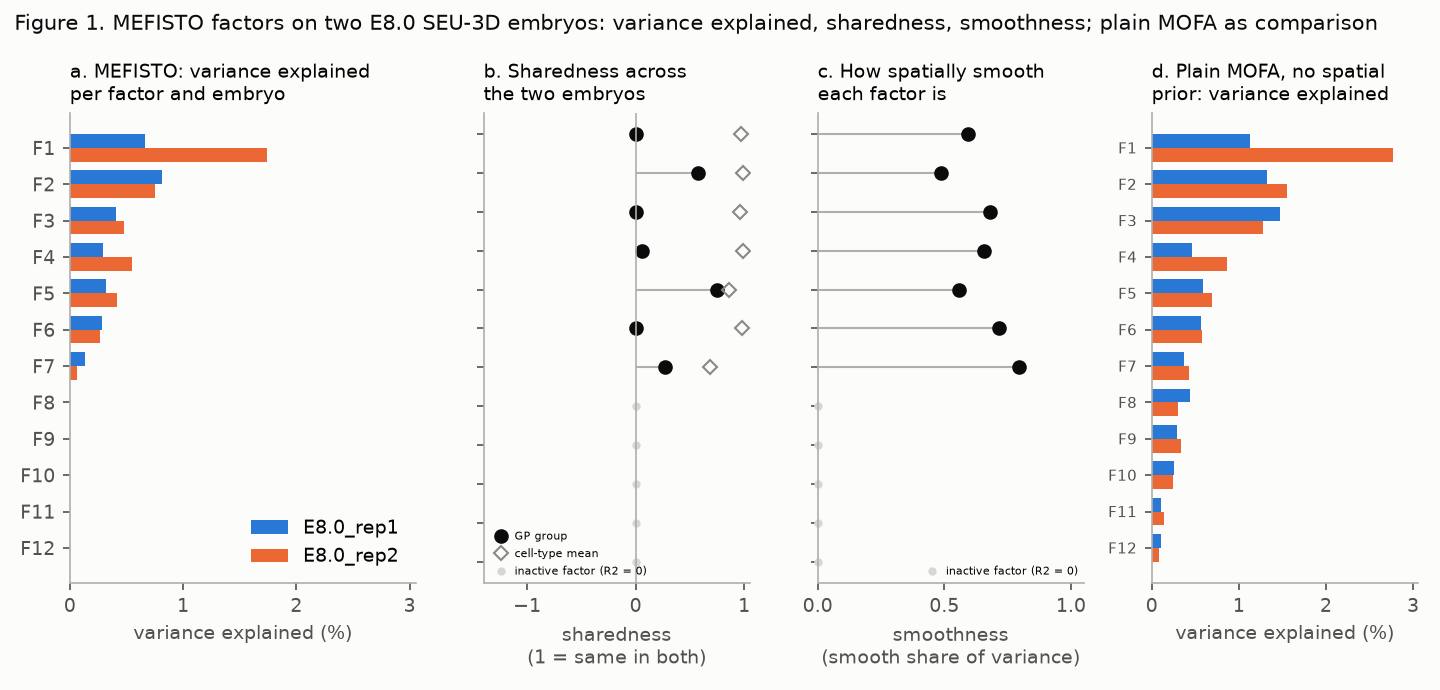

In [9]:
display(Image('figures/fig1_sharedness.png'))

What happened: the five dead factors are exactly the ones whose scale went to about 0 (0.05, 0.10, 0.01, 0.00, 0.11 vs 0.49 to 0.80 for the seven active), and they died rather than surviving as MOFA-like factors. After some digging, the first suspect was factor-level ARD- automatic relevance determination, the prior that puts a learned variance on each factor and lets the model shrink a factor to zero (switch it off) when it isn't pulling its weight. Turns out mofapy2 turns that off whenever covariates are given, and a refit with it explicitly off is bit-identical to this one, so that isn't it. The pruning has to come from the weight side instead: the same kind of shrinkage on W plus the spike-and-slab prior, which zero out a factor's weights gene by gene.

**Remaining unexplained:** as above, why the GP fitting path lets the weight-side shrinkage kill five factors that survive under MOFA.


## Notes- not where I am stuck, but useful to keep in mind

What the fit optimises and what I score it on are two different things. Both models maximise the ELBO: the expected log-likelihood of the data under the approximate posterior, minus the KL divergence from that posterior to the prior. The likelihood and the priors on the weights and the noise are shared between the two models- the only term that differs is the KL on the factors (independent normal for MOFA, Gaussian process for MEFISTO), so if hypothesis B above is right (the smooth prior discarding real structure), the mechanism has to live in that term. The sparse GP also makes MEFISTO's bound looser, so the final ELBOs below are not a controlled comparison.

R2 is a separate metric that neither model targets. If I optimised rank-K reconstruction R2 directly I would get PCA (in sample exactly; on held-out entries, close to it, with no priors and no factor pruning). So MOFA sitting closer to PCA than MEFISTO is partly just MOFA having the weaker prior, and is not by itself a verdict on which factors are more useful.


In [11]:
pd.Series({k: m['elbo'][~np.isnan(m['elbo'])][-1] for k, m in M.items()}, name='final ELBO').round(0)

MEFISTO   -2483314.0
MOFA      -2445410.0
Name: final ELBO, dtype: float64

MEFISTO's ELBO is lower, as expected from the looser bound- it says nothing about which fit is better.
